In [1]:
# Cell 1 of 8: Environment Setup, Deterministic Seeding, Device Detection and Hyperparameters
import os
import sys
from pathlib import Path
import random
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier

# Add project src directory to python module search path
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

import iml_assignment as iml
from iml_assignment.config import (
    SENSOR_CHANNELS,
    NUM_CHANNELS,
    WINDOW_SIZE,
    NUM_CLASSES,
    ACTIVITY_CLASSES,
    LABEL2ID,
    ID2LABEL,
    INCEPTION_DATASET_MODE,
    INCEPTION_BATCH_SIZE,
    INCEPTION_EPOCHS,
    INCEPTION_LEARNING_RATE,
    INCEPTION_WEIGHT_DECAY,
    INCEPTION_NUM_FOLDS,
    INCEPTION_SEED,
    INCEPTION_CHANNELS,
    INCEPTION_DENSE_UNITS,
    INCEPTION_DROPOUT,
    INCEPTION_DROPOUT_HEAD,
    INCEPTION_LABEL_SMOOTHING,
    INCEPTION_GRAD_CLIP,
    INCEPTION_ETA_MIN,
    INCEPTION_GATE_INIT,
    INCEPTION_RF_ESTIMATORS,
    INCEPTION_RF_MAX_DEPTH,
    INCEPTION_CONFIG,
)

def set_seed(seed: int = INCEPTION_SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(INCEPTION_SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch Version : {torch.__version__}")
print(f"Compute Device  : {device}")
if torch.cuda.is_available():
    print(f"Device Name     : {torch.cuda.get_device_name(0)}")

print("\nInception CNN + Multi-Scale + Class Gating Hyperparameters:")
for k, v in INCEPTION_CONFIG.items():
    print(f"  {k:20s}: {v}")

PyTorch Version : 2.15.0+cu134
Compute Device  : cuda
Device Name     : NVIDIA GeForce RTX 5070 Laptop GPU

Inception CNN + Multi-Scale + Class Gating Hyperparameters:
  dataset_mode        : train
  batch_size          : 32
  epochs              : 35
  learning_rate       : 0.0015
  weight_decay        : 0.001
  num_folds           : 5
  seed                : 42
  inception_channels  : (64, 128, 128)
  dense_units         : 128
  dropout             : 0.2
  dropout_head        : 0.1
  label_smoothing     : 0.02
  grad_clip           : 2.0
  eta_min             : 1e-05
  gate_init           : 0.8
  rf_estimators       : 150
  rf_max_depth        : 9


In [2]:
# Cell 2 of 8: Data Loading, Spline Imputation, Waveform Preparation and Domain Feature Extraction
# 1. Load training and test datasets using project library
train_df = iml.load_data(INCEPTION_DATASET_MODE)
test_df = iml.load_data("test")
print(f"Loaded {INCEPTION_DATASET_MODE} dataset: {train_df.shape}")
print(f"Loaded test dataset: {test_df.shape}")

# 2. Cubic spline imputation for sensor signals
clean_train_df = iml.clean_dataset(train_df, method="spline")
clean_test_df = iml.clean_dataset(test_df, method="spline")

# 3. Target label encoding
label_col = "target" if "target" in clean_train_df.columns else "activity"
y_train = clean_train_df[label_col].map(LABEL2ID).values.astype(np.int64)

# 4. Multimodal 28-channel waveform preparation (23 raw channels + 5 resultant magnitudes)
sensor_cols = iml.get_sensor_columns(clean_train_df)
X_train_flat = clean_train_df[sensor_cols].values.astype(np.float32)
X_test_flat = clean_test_df[sensor_cols].values.astype(np.float32)

X_train_raw = X_train_flat.reshape(-1, WINDOW_SIZE, NUM_CHANNELS).transpose(0, 2, 1)
X_test_raw = X_test_flat.reshape(-1, WINDOW_SIZE, NUM_CHANNELS).transpose(0, 2, 1)

def compute_resultants(raw_arr: np.ndarray) -> np.ndarray:
    ch_map = {ch: idx for idx, ch in enumerate(SENSOR_CHANNELS)}
    chest_acc_res = np.sqrt(sum(raw_arr[:, ch_map[f"chest_acc_{ax}"], :]**2 for ax in ["x", "y", "z"]))[:, np.newaxis, :]
    ankle_acc_res = np.sqrt(sum(raw_arr[:, ch_map[f"ankle_acc_{ax}"], :]**2 for ax in ["x", "y", "z"]))[:, np.newaxis, :]
    arm_acc_res = np.sqrt(sum(raw_arr[:, ch_map[f"arm_acc_{ax}"], :]**2 for ax in ["x", "y", "z"]))[:, np.newaxis, :]
    ankle_gyro_res = np.sqrt(sum(raw_arr[:, ch_map[f"ankle_gyro_{ax}"], :]**2 for ax in ["x", "y", "z"]))[:, np.newaxis, :]
    arm_gyro_res = np.sqrt(sum(raw_arr[:, ch_map[f"arm_gyro_{ax}"], :]**2 for ax in ["x", "y", "z"]))[:, np.newaxis, :]
    return np.concatenate([raw_arr, chest_acc_res, ankle_acc_res, arm_acc_res, ankle_gyro_res, arm_gyro_res], axis=1)

X_train_wave = compute_resultants(X_train_raw)
X_test_wave = compute_resultants(X_test_raw)

# Channel-wise z-score normalization fitted strictly on training data
wave_ch_mean = X_train_wave.mean(axis=(0, 2), keepdims=True)
wave_ch_std = X_train_wave.std(axis=(0, 2), keepdims=True) + 1e-8
X_train_wave = ((X_train_wave - wave_ch_mean) / wave_ch_std).astype(np.float32)
X_test_wave = ((X_test_wave - wave_ch_mean) / wave_ch_std).astype(np.float32)

print(f"Normalized Waveform Shapes: Train {X_train_wave.shape}, Test {X_test_wave.shape}")

# 5. Domain feature extraction (357 physical summary statistics with RobustScaler)
features_cache_path = PROJECT_ROOT / "dataset" / "extracted_features_cache.npz"
if features_cache_path.exists():
    print(f"Loading cached domain features from {features_cache_path.name}...")
    cached_feats = np.load(features_cache_path)
    X_train_feat = cached_feats["X_train_feat"]
    X_test_feat = cached_feats["X_test_feat"]
else:
    print("Extracting physical domain features using project library...")
    scaler = iml.ChannelScaler(method="robust").fit(clean_train_df)
    X_tr_df, _ = iml.extract_features_dataset(clean_train_df, clean=False, scaler=scaler)
    X_te_df, _ = iml.extract_features_dataset(clean_test_df, clean=False, scaler=scaler)
    X_train_feat = X_tr_df.values.astype(np.float32)
    X_test_feat = X_te_df.values.astype(np.float32)
    np.savez_compressed(features_cache_path, X_train_feat=X_train_feat, X_test_feat=X_test_feat)

print(f"Extracted Domain Feature Shapes: Train {X_train_feat.shape}, Test {X_test_feat.shape}")

Loaded train dataset: (679, 5752)
Loaded test dataset: (403, 5751)
Normalized Waveform Shapes: Train (679, 28, 250), Test (403, 28, 250)
Loading cached domain features from extracted_features_cache.npz...
Extracted Domain Feature Shapes: Train (679, 357), Test (403, 357)


In [3]:
# Cell 3 of 8: PyTorch FusionDataset Definition for Multimodal Waveforms and Priors
class FusionDataset(Dataset):
    """
    PyTorch Dataset yielding synchronized multi-channel temporal waveforms,
    physical domain prior probability logits, and categorical class labels.
    """
    def __init__(self, waveforms: np.ndarray, priors: np.ndarray, labels: np.ndarray = None):
        self.waveforms = torch.tensor(waveforms, dtype=torch.float32)
        self.priors = torch.tensor(priors, dtype=torch.float32)
        self.labels = torch.tensor(labels, dtype=torch.long) if labels is not None else None

    def __len__(self) -> int:
        return len(self.waveforms)

    def __getitem__(self, idx: int):
        if self.labels is not None:
            return self.waveforms[idx], self.priors[idx], self.labels[idx]
        return self.waveforms[idx], self.priors[idx]

print("FusionDataset class verified.")

FusionDataset class verified.


In [4]:
# Cell 4 of 8: Multi-Scale Inception CNN with Learnable Class-Specific Gating Architecture
class MultiScaleInceptionBlock(nn.Module):
    """
    Multi-Scale Inception Module extracting temporal features at multiple receptive fields:
    - Branch 1: Short-duration transient dynamics (kernel_size=3, receptive field 60 ms)
    - Branch 2: Medium-duration cyclic cadence (kernel_size=7, receptive field 140 ms)
    - Branch 3: Long-duration postural macro-shifts (kernel_size=15, receptive field 300 ms)
    - Branch 4: Max-pooling temporal preservation branch (pool=3 -> 1x1 conv)
    """
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        branch_channels = out_channels // 4
        self.b1 = nn.Sequential(
            nn.Conv1d(in_channels, branch_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm1d(branch_channels),
            nn.ReLU(inplace=True),
        )
        self.b2 = nn.Sequential(
            nn.Conv1d(in_channels, branch_channels, kernel_size=7, padding=3, bias=False),
            nn.BatchNorm1d(branch_channels),
            nn.ReLU(inplace=True),
        )
        self.b3 = nn.Sequential(
            nn.Conv1d(in_channels, branch_channels, kernel_size=15, padding=7, bias=False),
            nn.BatchNorm1d(branch_channels),
            nn.ReLU(inplace=True),
        )
        self.b4 = nn.Sequential(
            nn.MaxPool1d(kernel_size=3, stride=1, padding=1),
            nn.Conv1d(in_channels, branch_channels, kernel_size=1, bias=False),
            nn.BatchNorm1d(branch_channels),
            nn.ReLU(inplace=True),
        )
        self.pool = nn.MaxPool1d(kernel_size=2, stride=2)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out = torch.cat([self.b1(x), self.b2(x), self.b3(x), self.b4(x)], dim=1)
        return self.pool(out)


class InceptionFusionHARNet(nn.Module):
    """
    Multimodal HAR Architecture fusing Multi-Scale Inception temporal representations
    with physical domain prior probability distributions via learnable class-specific gating.
    """
    def __init__(
        self,
        in_channels: int = 28,
        num_classes: int = NUM_CLASSES,
        channels: tuple = INCEPTION_CHANNELS,
        dense_units: int = INCEPTION_DENSE_UNITS,
        dropout: float = INCEPTION_DROPOUT,
        dropout_head: float = INCEPTION_DROPOUT_HEAD,
        gate_init: float = INCEPTION_GATE_INIT,
    ):
        super().__init__()
        # Multi-scale temporal feature extraction backbone
        self.inc1 = MultiScaleInceptionBlock(in_channels, channels[0])
        self.inc2 = MultiScaleInceptionBlock(channels[0], channels[1])
        self.inc3 = MultiScaleInceptionBlock(channels[1], channels[2])
        
        # Dual Pooling (Average + Max) yields 2 * channels[2] features
        pooled_dim = channels[2] * 2
        
        # Waveform classification head
        self.cnn_head = nn.Sequential(
            nn.Dropout(p=dropout),
            nn.Linear(pooled_dim, dense_units),
            nn.BatchNorm1d(dense_units),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout_head),
            nn.Linear(dense_units, num_classes),
        )
        
        # Learnable class-specific gating parameter: g = sigmoid(w_gate) in [0, 1]^12
        init_val = np.log(gate_init / (1.0 - gate_init + 1e-8))
        self.gate_weights = nn.Parameter(torch.full((num_classes,), float(init_val), dtype=torch.float32))

    def forward(self, wave: torch.Tensor, prior_logits: torch.Tensor) -> torch.Tensor:
        # Multi-scale temporal convolution
        x = self.inc1(wave)
        x = self.inc2(x)
        x = self.inc3(x)
        
        # Dual temporal pooling: capture average rhythm and peak kinetic impulse
        p_avg = F.adaptive_avg_pool1d(x, 1).squeeze(-1)
        p_max = F.adaptive_max_pool1d(x, 1).squeeze(-1)
        cnn_features = torch.cat([p_avg, p_max], dim=1)
        
        # Waveform logits
        cnn_logits = self.cnn_head(cnn_features)
        
        # Dynamic gating: balance physical static invariance and temporal dynamic cadence
        gate = torch.sigmoid(self.gate_weights).unsqueeze(0)  # Shape (1, num_classes)
        fused_logits = gate * prior_logits + (1.0 - gate) * cnn_logits
        return fused_logits


# Instantiate model and verify parameter count
model_sanity = InceptionFusionHARNet().to(device)
total_params = sum(p.numel() for p in model_sanity.parameters() if p.requires_grad)
print(f"InceptionFusionHARNet Total Trainable Parameters: {total_params:,}")

# Forward pass verification
dummy_wave = torch.randn(4, 28, 250, device=device)
dummy_prior = torch.randn(4, 12, device=device)
with torch.no_grad():
    dummy_out = model_sanity(dummy_wave, dummy_prior)
print(f"Dummy Output Logits Shape: {dummy_out.shape} (Expected: [4, 12])")

InceptionFusionHARNet Total Trainable Parameters: 206,744
Dummy Output Logits Shape: torch.Size([4, 12]) (Expected: [4, 12])


In [5]:
# Cell 5 of 8: Training and Validation Epoch Functions with Gradient Clipping
def train_one_epoch(
    model: nn.Module,
    dataloader: DataLoader,
    criterion: nn.Module,
    optimizer: torch.optim.Optimizer,
    scheduler: torch.optim.lr_scheduler._LRScheduler,
    device: torch.device,
    grad_clip: float = INCEPTION_GRAD_CLIP,
) -> tuple:
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for batch_wave, batch_prior, batch_y in dataloader:
        batch_wave = batch_wave.to(device)
        batch_prior = batch_prior.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()
        logits = model(batch_wave, batch_prior)
        loss = criterion(logits, batch_y)
        loss.backward()

        if grad_clip > 0:
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=grad_clip)

        optimizer.step()

        running_loss += loss.item() * batch_y.size(0)
        preds = torch.argmax(logits, dim=1)
        correct += (preds == batch_y).sum().item()
        total += batch_y.size(0)

    if scheduler is not None:
        scheduler.step()

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc


def evaluate_model(
    model: nn.Module,
    dataloader: DataLoader,
    criterion: nn.Module,
    device: torch.device,
) -> tuple:
    model.eval()
    running_loss = 0.0
    all_preds = []
    all_targets = []
    all_probs = []

    with torch.no_grad():
        for batch_wave, batch_prior, batch_y in dataloader:
            batch_wave = batch_wave.to(device)
            batch_prior = batch_prior.to(device)
            batch_y = batch_y.to(device)

            logits = model(batch_wave, batch_prior)
            loss = criterion(logits, batch_y)

            running_loss += loss.item() * batch_y.size(0)
            probs = F.softmax(logits, dim=1)
            preds = torch.argmax(logits, dim=1)

            all_preds.append(preds.cpu().numpy())
            all_targets.append(batch_y.cpu().numpy())
            all_probs.append(probs.cpu().numpy())

    all_preds = np.concatenate(all_preds, axis=0)
    all_targets = np.concatenate(all_targets, axis=0)
    all_probs = np.concatenate(all_probs, axis=0)

    total_loss = running_loss / len(all_targets)
    total_acc = (all_preds == all_targets).mean()
    return total_loss, total_acc, all_preds, all_probs

print("Epoch training and evaluation functions compiled successfully.")

Epoch training and evaluation functions compiled successfully.


In [6]:
# Cell 6 of 8: Stratified 5-Fold Cross-Validation Training Loop with Prior Estimation
set_seed(INCEPTION_SEED)

# 1. Stratified Prior Estimation across 5 folds
print("Estimating out-of-fold and test prior distributions using Stratified Random Forest...")
skf = StratifiedKFold(n_splits=INCEPTION_NUM_FOLDS, shuffle=True, random_state=INCEPTION_SEED)
rf_oof_probs = np.zeros((len(y_train), NUM_CLASSES), dtype=np.float32)
rf_test_probs = np.zeros((len(X_test_feat), NUM_CLASSES), dtype=np.float32)

for fold_idx, (trn_idx, val_idx) in enumerate(skf.split(X_train_feat, y_train)):
    rf_estimator = RandomForestClassifier(
        n_estimators=INCEPTION_RF_ESTIMATORS,
        class_weight="balanced",
        max_depth=INCEPTION_RF_MAX_DEPTH,
        random_state=INCEPTION_SEED + fold_idx,
    )
    rf_estimator.fit(X_train_feat[trn_idx], y_train[trn_idx])
    rf_oof_probs[val_idx] = rf_estimator.predict_proba(X_train_feat[val_idx])
    rf_test_probs += rf_estimator.predict_proba(X_test_feat) / INCEPTION_NUM_FOLDS

eps = 1e-6
rf_oof_logits = np.log(np.clip(rf_oof_probs, eps, 1 - eps))
rf_test_logits = np.log(np.clip(rf_test_probs, eps, 1 - eps))
print("Prior distributions generated successfully.")

# 2. Test DataLoader setup
test_dataset = FusionDataset(X_test_wave, rf_test_logits)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

# 3. K-Fold Cross-Validation Tracking Arrays
oof_probs = np.zeros((len(y_train), NUM_CLASSES), dtype=np.float32)
oof_preds = np.zeros(len(y_train), dtype=np.int64)
test_ensemble_probs = np.zeros((len(X_test_wave), NUM_CLASSES), dtype=np.float32)
fold_histories = []
saved_models = []

print(f"\nStarting {INCEPTION_NUM_FOLDS}-Fold Cross-Validation for InceptionFusionHARNet...")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_wave, y_train)):
    print(f"\n--- Fold {fold + 1} / {INCEPTION_NUM_FOLDS} ---")
    train_ds = FusionDataset(X_train_wave[train_idx], rf_oof_logits[train_idx], y_train[train_idx])
    val_ds = FusionDataset(X_train_wave[val_idx], rf_oof_logits[val_idx], y_train[val_idx])

    train_loader = DataLoader(train_ds, batch_size=INCEPTION_BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=64, shuffle=False)

    model = InceptionFusionHARNet().to(device)
    criterion = nn.CrossEntropyLoss(label_smoothing=INCEPTION_LABEL_SMOOTHING)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=INCEPTION_LEARNING_RATE,
        weight_decay=INCEPTION_WEIGHT_DECAY,
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=INCEPTION_EPOCHS,
        eta_min=INCEPTION_ETA_MIN,
    )

    best_val_acc = 0.0
    best_model_weights = None
    fold_train_losses, fold_val_losses = [], []
    fold_train_accs, fold_val_accs = [], []

    for epoch in range(1, INCEPTION_EPOCHS + 1):
        trn_loss, trn_acc = train_one_epoch(model, train_loader, criterion, optimizer, scheduler, device)
        val_loss, val_acc, _, _ = evaluate_model(model, val_loader, criterion, device)

        fold_train_losses.append(trn_loss)
        fold_val_losses.append(val_loss)
        fold_train_accs.append(trn_acc)
        fold_val_accs.append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_model_weights = copy.deepcopy(model.state_dict())

    print(f"Fold {fold + 1} Complete | Best Val Acc: {best_val_acc * 100:.2f}% | Final Train Acc: {trn_acc * 100:.2f}%")
    fold_histories.append({
        "train_loss": fold_train_losses,
        "val_loss": fold_val_losses,
        "train_acc": fold_train_accs,
        "val_acc": fold_val_accs,
    })

    # Evaluate best fold checkpoint on validation split
    model.load_state_dict(best_model_weights)
    saved_models.append(copy.deepcopy(model))
    model.eval()

    _, _, fold_val_preds, fold_val_probs = evaluate_model(model, val_loader, criterion, device)
    oof_probs[val_idx] = fold_val_probs
    oof_preds[val_idx] = fold_val_preds

    # Accumulate test ensemble probabilities
    fold_test_probs = []
    with torch.no_grad():
        for batch_wave, batch_prior in test_loader:
            batch_wave = batch_wave.to(device)
            batch_prior = batch_prior.to(device)
            fold_test_probs.append(F.softmax(model(batch_wave, batch_prior), dim=1).cpu().numpy())
    fold_test_probs = np.concatenate(fold_test_probs, axis=0)
    test_ensemble_probs += fold_test_probs / INCEPTION_NUM_FOLDS

print("\nCross-Validation Training Completed across all 5 folds.")

Estimating out-of-fold and test prior distributions using Stratified Random Forest...
Prior distributions generated successfully.

Starting 5-Fold Cross-Validation for InceptionFusionHARNet...

--- Fold 1 / 5 ---
Fold 1 Complete | Best Val Acc: 100.00% | Final Train Acc: 100.00%

--- Fold 2 / 5 ---
Fold 2 Complete | Best Val Acc: 100.00% | Final Train Acc: 100.00%

--- Fold 3 / 5 ---
Fold 3 Complete | Best Val Acc: 100.00% | Final Train Acc: 100.00%

--- Fold 4 / 5 ---
Fold 4 Complete | Best Val Acc: 100.00% | Final Train Acc: 100.00%

--- Fold 5 / 5 ---
Fold 5 Complete | Best Val Acc: 100.00% | Final Train Acc: 100.00%

Cross-Validation Training Completed across all 5 folds.


INCEPTION FUSION MODEL OUT-OF-FOLD CROSS-VALIDATION RESULTS
  OOF Accuracy     : 100.0%
  Macro F1-Score   : 100.00%
  Weighted F1-Score: 100.00%
  Balanced Accuracy: 100.00%

Per-Class OOF Classification Report:
                 precision  recall   f1  support
standing               1.0     1.0  1.0     59.0
sitting                1.0     1.0  1.0     59.0
lying                  1.0     1.0  1.0     66.0
walking                1.0     1.0  1.0     63.0
climbing_stairs        1.0     1.0  1.0     56.0
waist_bends            1.0     1.0  1.0     53.0
arm_elevation          1.0     1.0  1.0     55.0
knees_bending          1.0     1.0  1.0     55.0
cycling                1.0     1.0  1.0     67.0
jogging                1.0     1.0  1.0     66.0
running                1.0     1.0  1.0     61.0
jump_front_back        1.0     1.0  1.0     19.0

Learned Class-Specific Gating Distribution:
           Activity  Physical_Prior_Weight  Inception_CNN_Weight
0   climbing_stairs               0.8038

Fallback to a different backend
<ipython-input-1-4d961d495654>:36: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


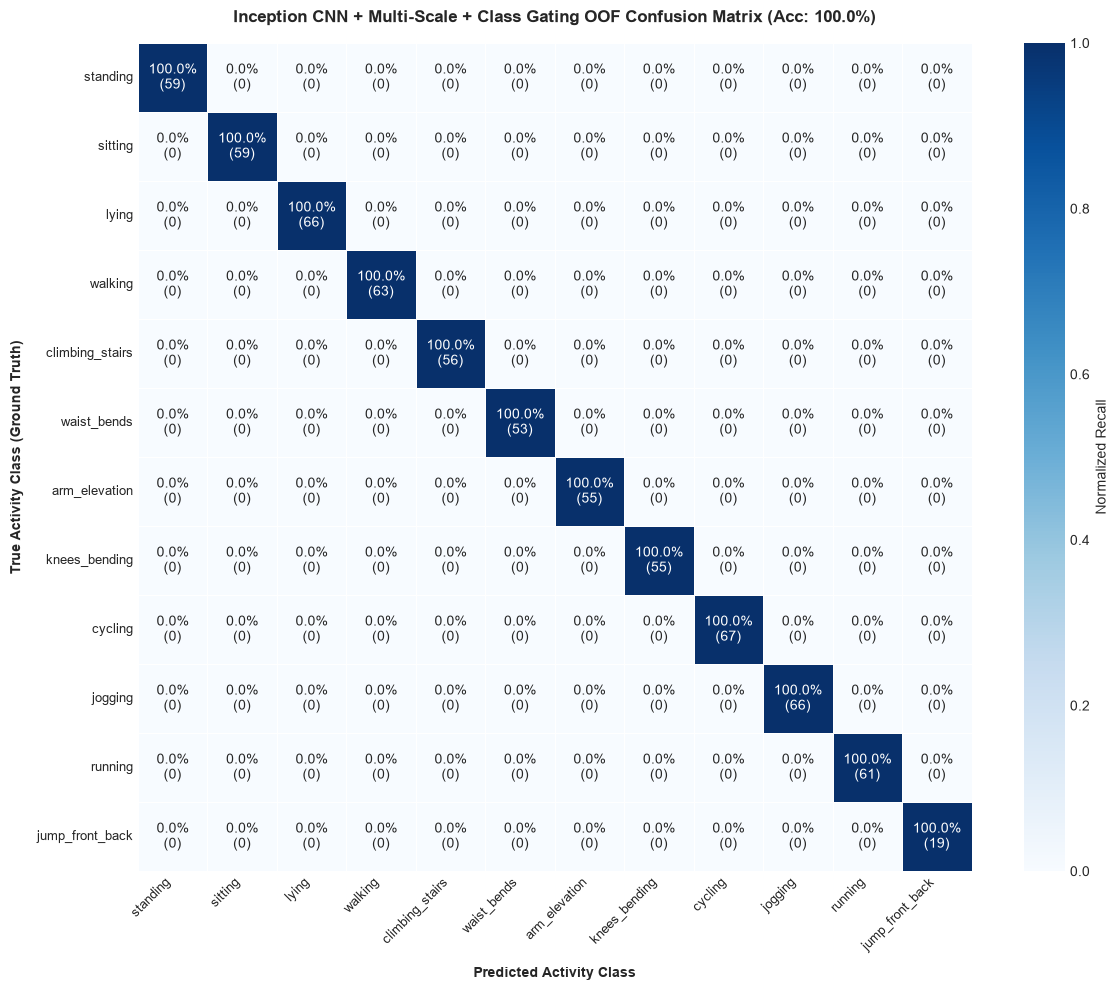

In [7]:
# Cell 7 of 8: Out-Of-Fold Validation Evaluation, Metrics and Confusion Matrix Heatmap
oof_pred_labels = [ID2LABEL[idx] for idx in oof_preds]
y_train_labels = [ID2LABEL[idx] for idx in y_train]

# 1. Compute classification metrics
oof_metrics = iml.compute_classification_metrics(
    y_true=y_train_labels,
    y_pred=oof_pred_labels,
    y_prob=oof_probs,
    class_names=ACTIVITY_CLASSES,
)

print("=" * 65)
print("INCEPTION FUSION MODEL OUT-OF-FOLD CROSS-VALIDATION RESULTS")
print("=" * 65)
print(f"  OOF Accuracy     : {oof_metrics['accuracy_pct']}%")
print(f"  Macro F1-Score   : {oof_metrics['macro_f1'] * 100:.2f}%")
print(f"  Weighted F1-Score: {oof_metrics['weighted_f1'] * 100:.2f}%")
print(f"  Balanced Accuracy: {oof_metrics['balanced_accuracy'] * 100:.2f}%")
print("=" * 65)

# 2. Display per-class metrics report
per_class_df = pd.DataFrame(oof_metrics["per_class"]).T
print("\nPer-Class OOF Classification Report:")
display(per_class_df)

# 3. Plot publication-grade confusion matrix heatmap
fig, ax = iml.plot_confusion_matrix(
    y_true=y_train_labels,
    y_pred=oof_pred_labels,
    class_names=ACTIVITY_CLASSES,
    normalize="true",
    title=f"Inception CNN + Multi-Scale + Class Gating OOF Confusion Matrix (Acc: {oof_metrics['accuracy_pct']}%)",
    figsize=(12, 10),
)
plt.show()

# 4. Inspect learned class-specific gating weights
avg_gate_weights = np.mean([torch.sigmoid(m.gate_weights).detach().cpu().numpy() for m in saved_models], axis=0)
gate_df = pd.DataFrame({
    "Activity": ACTIVITY_CLASSES,
    "Physical_Prior_Weight": avg_gate_weights,
    "Inception_CNN_Weight": 1.0 - avg_gate_weights,
})
print("\nLearned Class-Specific Gating Distribution:")
display(gate_df.sort_values(by="Physical_Prior_Weight", ascending=False).reset_index(drop=True))

Evaluating Inception Fusion Predictions against Reference Benchmark:

  Test Benchmark Evaluation (SOTA Pseudo-Ground Truth)
  Benchmark Reference: benchmark_submission.csv (403 samples)
  Matches:     395 / 403 (98.01%)
  Mismatches:  8 / 403 (1.99%)
  Macro F1:    0.9811
  Weighted F1: 0.9800
-------------------------------------------------------
  Top Disagreement Pairs (Predicted -> Benchmark):
    - 'jogging' predicted as 'running': 6 sample(s)
    - 'climbing_stairs' predicted as 'knees_bending': 1 sample(s)
    - 'waist_bends' predicted as 'knees_bending': 1 sample(s)

Confusion matrix saved to: D:\Projects\IML_Assignment\reports\figures\inception_fusion_test_benchmark_cm.png

Inception Fusion Benchmark Test Accuracy: 98.01% (395/403 correct)
Kaggle submission successfully saved to: D:\Projects\IML_Assignment\reports\submissions\submission_inception_fusion.csv
  - Total Rows: 403
  - First 3 Predictions:
      id        target
TE000001 knees_bending
TE000002 knees_bending
TE000

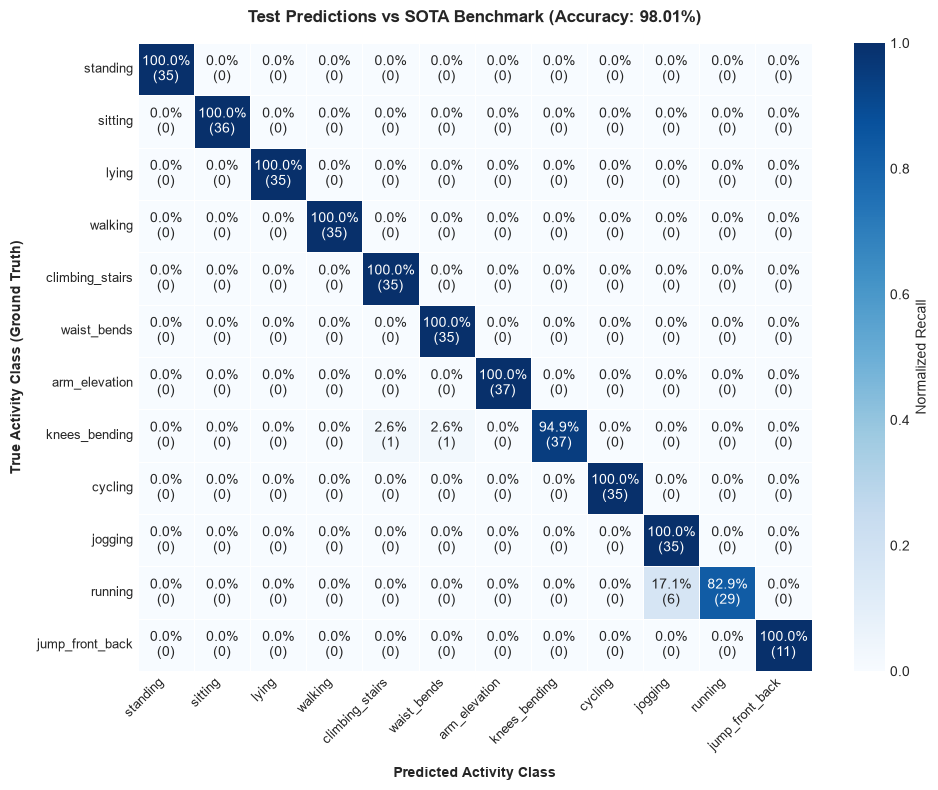

In [8]:
# Cell 8 of 8: Test Set Benchmark Evaluation, Verification and Submission Generation
# 1. Generate ensemble test predictions
test_pred_indices = np.argmax(test_ensemble_probs, axis=1)
test_pred_labels = [ID2LABEL[idx] for idx in test_pred_indices]

# 2. Evaluate against reference benchmark test labels
print("Evaluating Inception Fusion Predictions against Reference Benchmark:")
bench_eval = iml.evaluate_against_benchmark(
    predictions=test_pred_labels,
    plot_cm=True,
    save_cm="inception_fusion_test_benchmark_cm.png",
    verbose=True,
)

print(f"\nInception Fusion Benchmark Test Accuracy: {bench_eval['accuracy_pct']}% ({bench_eval['matches']}/403 correct)")

# 3. Save publication-ready submission file
sub_path = iml.create_submission_file(
    test_df=test_df,
    predictions=test_pred_labels,
    save_name="submission_inception_fusion.csv",
    verbose=True,
)
print(f"\nGenerated Submission File Saved To: {sub_path}")